In [1]:
import numpy as np
import matplotlib.pyplot as plt
import perceval as pcvl

plt.rcParams.update({"figure.figsize": (6, 4), "font.size": 12,
                     "axes.grid": True, "grid.alpha": 0.3})
print("perceval", pcvl.__version__)

# Crisp plots on projectors and HiDPI screens (works on Colab too).
%config InlineBackend.figure_format = "retina"

perceval 1.2.4


### Perceval: básicos

O perceval é uma biblioteca/framework que permite você acessar e simular computadores quânticos fotônicos. 

A arquitetura desse computador é ilustrada a seguir (imagem tirada das lecture notes do Tim):


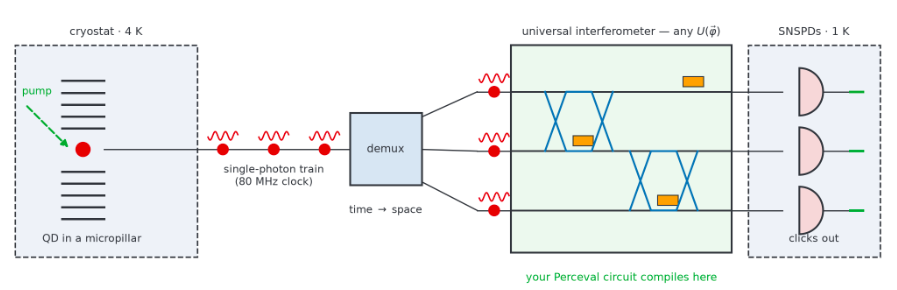

* Ponto quântico que gera fótons únicos sob demanda;
* Time demultiplexer que transmite os fótons para os modos definidos;
* O chip fotônico é um interferométro universal (), capaz de reproduzir qualquer porta lógica (até 12x12);
* O medidor é um sensor superconductor (superconducting nanowire single-photon detectors - SNSPD);


Para mais informações a respeito da arquitetura do esquema fotônico da Quandela: *A versatile single-photon-based quantum
computing platform*, Maring N. (2024)



Os primeiros conceitos necessários para nós são de **estados** e **modos**. 
Os modos correspondem aos caminhos ópticos disponíveis para os fótons e são realizados fisicamente por guias de ondas (ou fibras ópticas). Já o estado é definido na base de Fock, possibilitando definir o número de fótons para cada modo possível.


In [2]:
### Definindo estados Fock:
estado = pcvl.BasicState([1,0]); ket = pcvl.BasicState('|1,0>') 

estado2 = pcvl.BasicState([1,0,0,2,10,20,80])

(print(f"Estado 1:{estado}, Ket:{ket}"))
print(f'Número de fótons: {estado.n}')
print(f'Número de modos: {estado.m}')
print('---'*10)

print(f'Estado 2: {estado2}')
print(f'Número de fótons: {estado2.n}')
print(f'Número de modos: {estado2.m}')

### Na simulação não há restrição de modo e número de fótons, porém nos computadores disponíveis é necessário se 
### atentar as restrições.

Estado 1:|1,0>, Ket:|1,0>
Número de fótons: 1
Número de modos: 2
------------------------------
Estado 2: |1,0,0,2,10,20,80>
Número de fótons: 113
Número de modos: 7


In [3]:
## Podemos manipular esse estado:
estado12 = estado*estado2
print(f"|Estado 1>|Estado 2> = {estado12}")
print(f'Número de fótons: {estado12.n}')
print(f'Número de modos: {estado12.m}')

|Estado 1>|Estado 2> = |1,0,1,0,0,2,10,20,80>
Número de fótons: 114
Número de modos: 9


#### Circuitos e componentes:

Os circuitos consiste dos modos espaciais e componentes ópticos que escolhemos utilizar. Esse circuito guia os fótons definidos pelo estado e os componentes atuam nesses fótons.  

O primeiro componente a ser apresentado é o divisor de feixes:

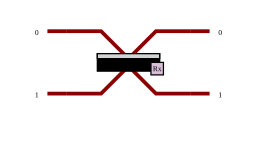

In [4]:
### Tendo definido os estados, podemos construir o sistema óptico que estamos utilizando
# Definimos dois caminhos (dois modos espaciais) e um Beam-Splitter


circuit = pcvl.Circuit(2) // pcvl.BS()

display(pcvl.pdisplay(circuit))

In [5]:
### Podemos ainda olhar para essas portas simbolicamente:

div_feixes = pcvl.BS()
print()
pcvl.pdisplay(div_feixes.definition())

<IPython.core.display.Math object>

Note que um divisor de feixes é parametrizado pelos ângulos:
* $\theta$: define a transmitância e refletividade:
$$
T = cos^2(\theta) \\ R = sin^2(\theta)
$$
* $\phi$: fases de cada uma das entradas e saídas do divisor de feixes:
    * $\phi_{tl}$: Topo esquerdo;
    * $\phi_{tr}$: Topo esquerdo;
    * $\phi_{dl}$: Topo esquerdo;
    * $\phi_{dr}$: Topo esquerdo;
    
    
Por padrão: $\theta = np.pi/2$ e $\phi_{tl} = \phi_{tr} = \phi_{dl} = \phi_{dr} = 0$

In [6]:
pcvl.pdisplay(div_feixes.compute_unitary()) # unitária padrão do divisor de feixes


<IPython.core.display.Math object>

In [7]:
# podemos nós mesmos definirmos valores para theta e phi:
bs = pcvl.BS(theta = np.pi/3,phi_tl = np.pi/5)
pcvl.pdisplay(bs.compute_unitary())

<IPython.core.display.Math object>

Outro importante componente é o deslocador de fases (*phase shifter*).

Temos aqui um detalhe importante, o erro máximo presente na definição do deslocador corresponde a um ruído inerente ao componente. Em simulações ele é nulo, mas podemos, também, definí-lo.

<IPython.core.display.Math object>

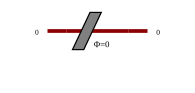

In [8]:
desloc_fase = pcvl.PS(phi = 0)### max_error = 1
pcvl.pdisplay(desloc_fase.definition())
pcvl.pdisplay(desloc_fase)

Ainda temos outros componentes que podem ser de interesse na simulação de experimentos, mas que a princípio não serão discutidos, por não serem usados nos exemplos a seguir:
* Placa de meia onda;
* Divisor de feixes polarizador;
* Atraso temporal;
* Canal de perda;

### Simulações:

Tendo já apresentado como definir estados, modos, componentes e circuitos, podemos começar a ver como obter resultados desses experimentos. 

Para rodar nossas simulações o Perceval disponibiliza uma série de *back-ends* que rodam **algoritmos** especifícos para simular nossos experimentos. Cada algoritmo tem suas vantagens e desvantagens no tempo de simulação e no tipo de simulação que gostariamos de realizar. Para efeitos práticos não iremos nos preocupar muito com isso agora (mas para uma discussão mais em detalhe o site da perceval tem especificações para cada um). 

Além do tipo de algoritmo que gostariamos de rodar podemos definir diferentes tipos de formas de simular esses circuitos: 

Back-ends: "SLOS", "CliffordClifford2017", "Naive", "NaiveApprox", "MPS" e "SLAP".

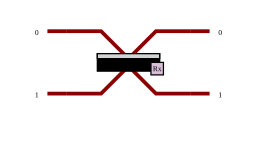

Probabilidades exatas:
  |0,1>: 0.500
  |1,0>: 0.500

1000 contagens (clicks!):
  |1,0>: 493
  |0,1>: 507

Probabilidades obtidas:
  |1,0>: 0.493
  |0,1>: 0.507


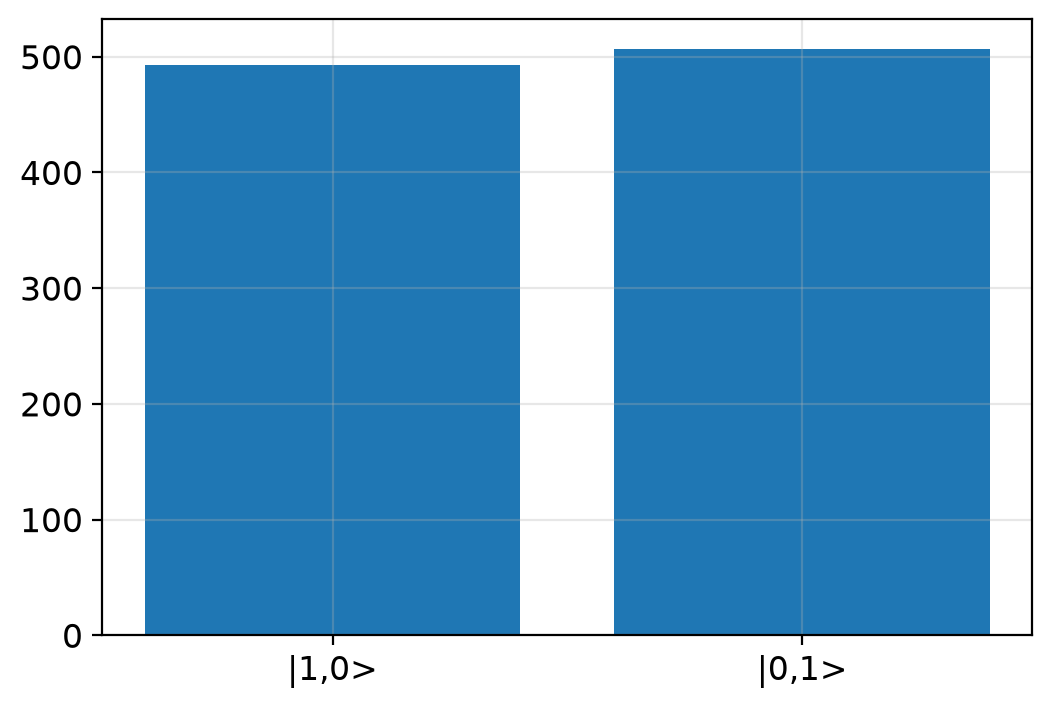

In [23]:
### Agora queremos ver os resultados de um experimento desse tipo:


estado = pcvl.BasicState('|1,0>')

theta = np.pi/2 ### Podemos alterar esse valor e verificar como a transmitância e a refletividade alteram o output
circuit = pcvl.Circuit(2) // pcvl.BS(theta = theta)
display(pcvl.pdisplay(circuit))


proc = pcvl.Processor("SLOS", circuit) # definimos o processador e o circuito que queremos rodar
                                       # SLOS é o simulador do processador deles;
    
proc.with_input(estado) # |1,0>: 1 fóton entra pelo caminho superior


sampler = pcvl.algorithm.Sampler(proc) # define um método para rodar os experimentos várias vezes

results = sampler.probs() # resultados


probs = results["results"] # define as probabilidades exatas (analíticas)
print("Probabilidades exatas:")
for state, p in probs.items():
    print(f"  {state}: {p:.3f}")

# Permite simular resultados "reais":
counts = sampler.sample_count(1000)["results"]
print("\n1000 contagens (clicks!):")
for state, c in counts.items():
    print(f"  {state}: {c}")
    
print('\nProbabilidades obtidas:')
for state,c in counts.items():
    print(f"  {state}: {c/1000}")
    
# podemos visualizar como um histograma:
plt.bar([str(state) for state in counts.keys()], counts.values())
plt.show()

Os processadores tem como padrão rodar circuitos ideais, sem considerar possíveis ruídos nos detectores, fontes, etc. Nos experimentos reais e nos próprios computadores uma série de imperfeições prejudicam os resultados. Também podemos considerar esses possíveis problemas quando rodamos nossos circuitos. Os modelos ruidosos desses processadores tem os seguintes paramêtros:

##### Ruído relacionado à fonte de fótons:

1. **brightness** — Perda na primeira etapa de geração de fótons. Representa quantos fótons entram com sucesso no sistema após a geração. Padrão: None (sem perda)

2. **indistinguishability** — Probabilidade de que dois fótons sejam indistinguíveis. Varia de 0 (completamente distinguíveis) a 1 (perfeitamente indistinguíveis). Padrão: None (perfeito)

3. **g²(0) (g2)** — Autocorrelação de intensidade de segunda ordem com delay nulo. Valores mais baixos = fonte mais pura de fótons únicos. Padrão: None

4. **g²_distinguishable (g2_distinguishable)** — Sinalizador booleano indicando se fótons gerados por g² são distinguíveis de fótons únicos. Padrão: None

##### Ruído do circuito/componentes:

5. **transmittance** — Perda global aplicada em todo o sistema óptico (através de divisores de feixes, guias de onda, etc.). Representa quantos fótons conseguem passar por todos os componentes. Padrão: None (sem perda)

6. **phase_imprecision** — Imprecisão máxima na calibração do deslocador de fase. Representa erros sistemáticos na definição da fase. Padrão: None

7. **phase_error** — Ruído aleatório máximo nos deslocadores de fase, modelando desvio térmico e jitter eletrônico nos aquecedores. Padrão: None



Probabilidades exatas:
  |0,1>: 0.350
  |1,0>: 0.350
  |0,0>: 0.300

1000 contagens (clicks!):
  |0,0>: 317
  |1,0>: 323
  |0,1>: 360

Probabilidades obtidas:
  |0,0>: 0.317
  |1,0>: 0.323
  |0,1>: 0.36

Performance global: 1.0


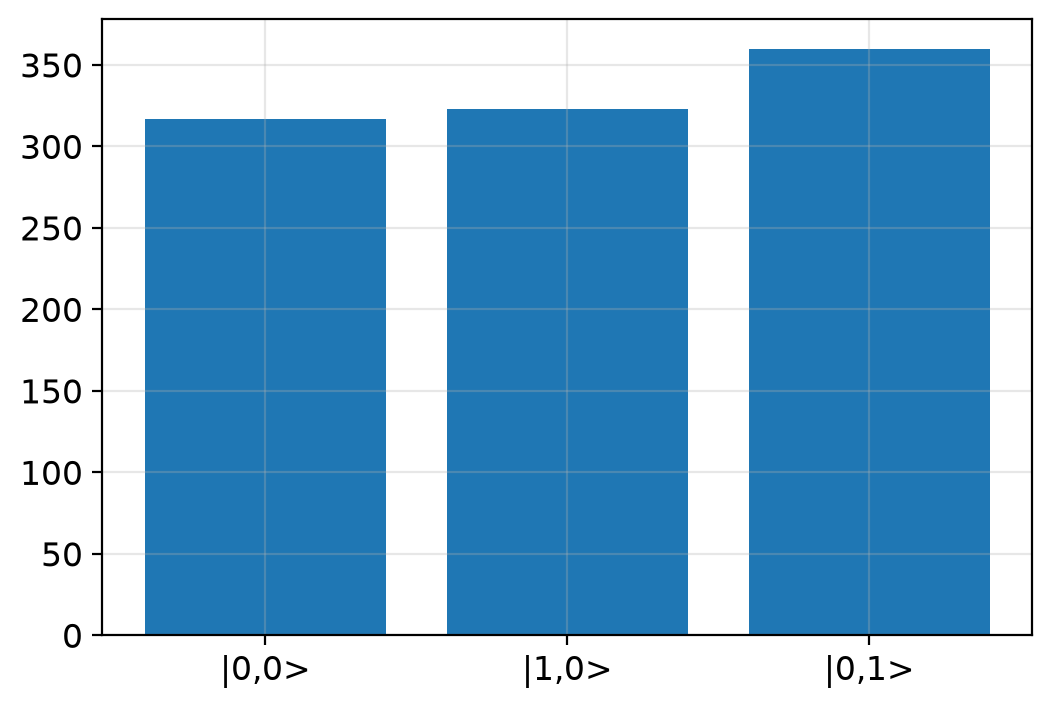

In [10]:


proc_ruido = pcvl.Processor("SLOS", circuit, noise= pcvl.NoiseModel(brightness = 0.70)) # definimos o processador e o circuito que queremos rodar
                                       # SLOS é o simulador do processador deles;
    
proc_ruido.with_input(estado) # |1,0>: 1 fóton entra pelo caminho superior

proc_ruido.min_detected_photons_filter(0)

sampler = pcvl.algorithm.Sampler(proc_ruido)  # define um método para rodar os experimentos várias vezes

results = sampler.probs() # resultados


probs = results["results"] # define as probabilidades exatas (analíticas)
print("Probabilidades exatas:")
for state, p in probs.items():
    print(f"  {state}: {p:.3f}")

# Permite simular resultados "reais":
counts = sampler.sample_count(1000)["results"]
print("\n1000 contagens (clicks!):")
for state, c in counts.items():
    print(f"  {state}: {c}")
    
print('\nProbabilidades obtidas:')
for state,c in counts.items():
    print(f"  {state}: {c/1000}")
    
    
    
print(f'\nPerformance global: {results["global_perf"]}')
    
# podemos visualizar como um histograma:
plt.bar([str(state) for state in counts.keys()], counts.values())
plt.show()

Podemos, porém, tentar melhorar os resultados obtidos filtrando as detecções que não possuem um número minímo de fótons. Nesse exemplo simples vamos escolher aceitar apenas os casos em que **pelo menos** um fóton foi medido. Você irá notar que o número de samples continuará somando a 1000, ou seja, o processador ignora os casos em que nenhum fóton foi medido e segue coletando samples. Porém, não saímos ilesos dessa operação, conseguimos mensurar o que fizemos através de uma métrica aliada ao **Sampler**: *global_performance*. 

obs.: essa global_performance é na verdade aliada a duas métricas: physical_performance * logical_performance. Para nós agora a única métrica que importa é a *physical_performance* e consideraremos *logical_performance* = 1.0;

Definimos 
$$
\text{physical_performance} = \frac{\text{N}^\circ\text{ de eventos em que o min. de fótons foi detectado}}{\text{N}^\circ\text{ total de eventos }}
$$

Probabilidades exatas:
  |0,1>: 0.500
  |1,0>: 0.500

1000 contagens (clicks!):
  |1,0>: 496
  |0,1>: 504

Probabilidades obtidas:
  |1,0>: 0.496
  |0,1>: 0.504

Performance global: 0.8


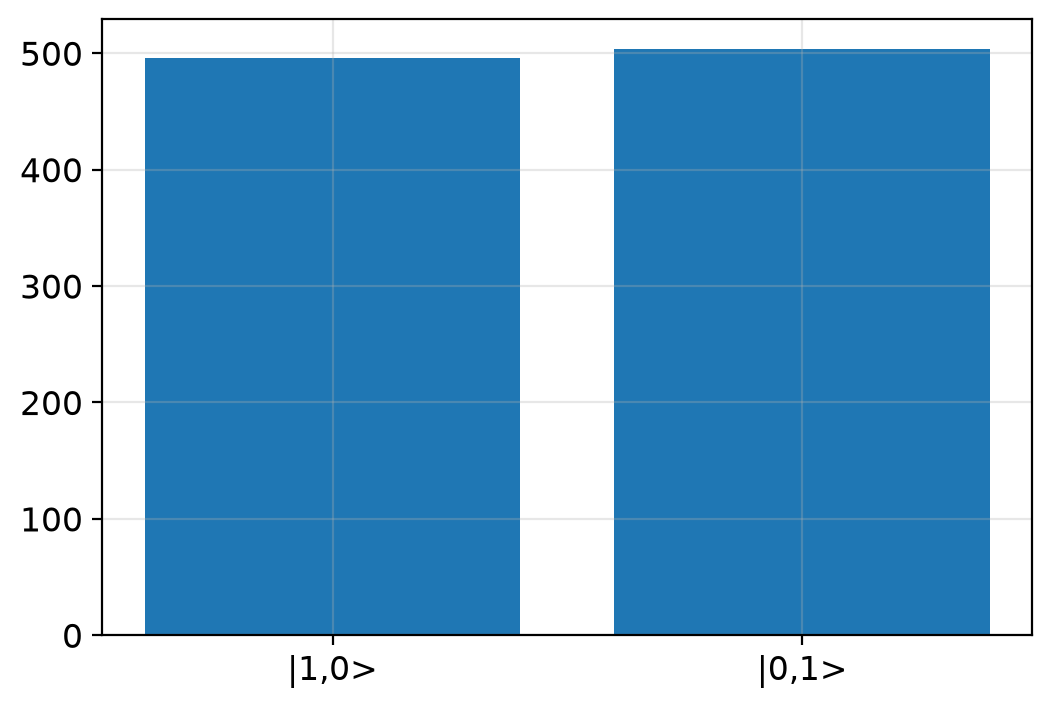

In [11]:


proc_ruido = pcvl.Processor("SLOS", circuit, noise= pcvl.NoiseModel(brightness = 0.80)) # definimos o processador e o circuito que queremos rodar
                                       # SLOS é o simulador do processador deles;
    
proc_ruido.with_input(estado) # |1,0>: 1 fóton entra pelo caminho superior

proc_ruido.min_detected_photons_filter(1)

sampler = pcvl.algorithm.Sampler(proc_ruido)  # define um método para rodar os experimentos várias vezes

results = sampler.probs() # resultados



probs = results["results"] # define as probabilidades exatas (analíticas)
print("Probabilidades exatas:")
for state, p in probs.items():
    print(f"  {state}: {p:.3f}")

# Permite simular resultados "reais":
n_sample = 1000
counts = sampler.sample_count(n_sample)["results"]
print("\n1000 contagens (clicks!):")
for state, c in counts.items():
    print(f"  {state}: {c}")
    
print('\nProbabilidades obtidas:')
for state,c in counts.items():
    print(f"  {state}: {c/n_sample}")
    
    
    
print(f'\nPerformance global: {results["global_perf"]}')
    
# podemos visualizar como um histograma:
plt.bar([str(state) for state in counts.keys()], counts.values())
plt.show()

Não irei entrar em mais detalhes a respeito de computação remota, utilizando os processadores disponíveis pela Quandela. O processo, porém requer que você se cadastre, defina um token individual que te permitirá acesso a nuvem da empresa. Embora o circuito não mudará muito, torna-se importante se atentar a topologia do circuito do chip acessado e restrições de modos, fótons, etc.

Tendo visto como simular circuitos vamos começar a discutir interferometros e experimentos já conhecidos. Isso vai nos ajudar a entender melhor o funcionamento geral dos próprios computadores da Quandela. 

### Interferometro de Mach-Zender

Agora vamos rodar nosso primeiro **experimento**: o interferomêtro de Mach-Zender. Esse interferometro nos interessa por dois motivos principais:
1. Experimento importante na história da Óptica Quântica e reproduz fenomênos, por exemplo, do interferométro de Michelson.
    * Um ponto importante é que não somos capazes de reproduzir experimentos como o de Michelson, já que o Perceval contém uma orientação direta no **tempo**.
2. Os computadores fotônicos da Quandela utilizam interferometros de Mach-Zender com phase-shifters. Isso porque em "Experimental Realization of Any Discrete Unitary Operator" foi mostrado como construir qualquer unitária NxN apenas com beam-splitters com ângulo (reflexividade) váriavsel e os phase-shifters. Algo que ficará claro adiante, mas um I.M.Z reproduz exatamente a variação da reflexividade do ângulo. 


A fim de completude vamos descrever o I.M.Z matematicamente. Poderiamos seguir dois caminhos, um , em que definimos o caminho superior e o inferior como possíveis estados do qubit ($|0\rangle$ e $|1\rangle$) e o BS e PS como matrizes. O que iremos fazer é uma descrição mais fiel a Óptica Quântica (na minha opinião):

Temos como base que o BS tem em cada um de seus 4 caminhos operadores do campo (de aniquilação).



# Interferômetro de Mach-Zehnder em Espaço de Fock

## 1. Circuito Básico

O interferômetro de Mach-Zehnder (M.Z) consiste em dois divisores de feixes conectados por dois caminhos ópticos com uma defasagem controlada.

**Componentes:**
- Dois beam splitters (BS)
- Um phase shifter (PS) em um dos caminhos
- Dois detectores nas saídas

## 2. Estado Inicial

Defina um estado inicial com um fóton na primeira entrada:

$$|\psi_0\rangle = |1,0\rangle$$

onde |1,0⟩ significa 1 fóton no modo 0 e 0 fótons no modo 1.

## 3. Primeiro Divisor de Feixes (BS₁)

O primeiro beam splitter atua transformando os operadores de aniquilação:

$$\hat{a}_2 = \frac{1}{\sqrt{2}}(\hat{a}_1 + i\hat{a}_3)$$

Aplicando ao estado inicial |1,0⟩:

$$\hat{a}_2^+ |0,0\rangle_1 = \frac{1}{\sqrt{2}}(\hat{a}_1 + i\hat{a}_3)|0,0\rangle_1$$

$$= \frac{1}{\sqrt{2}}(|1,0\rangle + i|0,1\rangle)$$

Após o primeiro BS, o fóton está em uma superposição igual dos dois modos com uma fase relativa.

## 4. Phase Shifter

Após o primeiro BS, aplicamos um phase shifter com ângulo φ em um dos caminhos:

$$|\psi_1\rangle = \frac{1}{\sqrt{2}}(|1,0\rangle + ie^{i\phi}|0,1\rangle)$$

## 5. Segundo Divisor de Feixes (BS₂)

O segundo beam splitter novamente atua como:

$$\hat{a}_3 = \frac{1}{\sqrt{2}}(i\hat{a}_1 + \hat{a}_2)$$

Aplicando ao estado superposicionado:

$$|\psi_2\rangle = \hat{a}_3^+ |\psi_1\rangle$$

Expandindo os termos:

$$= \frac{1}{2}[|1,0\rangle + ie^{i\phi}|0,1\rangle + ie^{i\phi}|0,1\rangle - e^{i\phi}|1,0\rangle]$$

$$= \frac{1}{2}[(1-e^{i\phi})|1,0\rangle + i(1+e^{i\phi})|0,1\rangle]$$

## 6. Probabilidades de Detecção

A probabilidade de detectar o fóton no modo 0 (reflexão):

$$P[|1,0\rangle] = |\langle 1,0|\psi_2\rangle|^2 = \left|\frac{1-e^{i\phi}}{2}\right|^2$$

$$= \frac{|1-e^{i\phi}|^2}{4} = \frac{2-2\cos\phi}{4} = \frac{1-\cos\phi}{2}$$

$$= \sin^2\left(\frac{\phi}{2}\right)$$

A probabilidade de detectar no modo 1 (transmissão):

$$P[|0,1\rangle] = |\langle 0,1|\psi_2\rangle|^2 = \left|\frac{i(1+e^{i\phi})}{2}\right|^2$$

$$= \frac{|1+e^{i\phi}|^2}{4} = \frac{2+2\cos\phi}{4} = \frac{1+\cos\phi}{2}$$

$$= \cos^2\left(\frac{\phi}{2}\right)$$

## 7. Identidades Trigonométricas

As seguintes identidades são úteis:

$$\cos 2\phi = \cos^2\phi - \sin^2\phi = 2\cos^2\phi - 1 = 1 - 2\sin^2\phi$$

$$\cos^2\phi = \frac{1+\cos 2\phi}{2}$$

$$\sin^2\phi = \frac{1-\cos 2\phi}{2}$$

## 8. Resultado Final: Padrão de Interferência

$$P(\text{Reflexão}) = P(|1,0\rangle) = \sin^2\left(\frac{\phi}{2}\right)$$

$$P(\text{Transmissão}) = P(|0,1\rangle) = \cos^2\left(\frac{\phi}{2}\right)$$

**Interpretação:**
- Para φ = 0: P(reflexão) = 0, P(transmissão) = 1 (interferência construtiva)
- Para φ = π: P(reflexão) = 1, P(transmissão) = 0 (interferência destrutiva)
- Para φ = π/2: P(reflexão) = P(transmissão) = 1/2 (divisão igual)



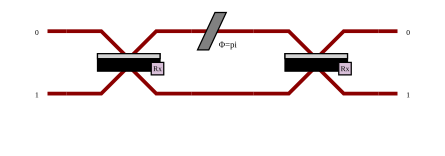

In [30]:
# One photon, one 50:50 beamsplitter.
def michelson(phi):
    return pcvl.Circuit(2)  // pcvl.BS() // pcvl.PS(phi) // pcvl.BS()

pcvl.pdisplay(michelson(np.pi))

Vamos ver o que acontece quando variamos a fase do Phase-Shifter.

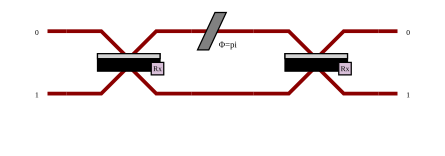

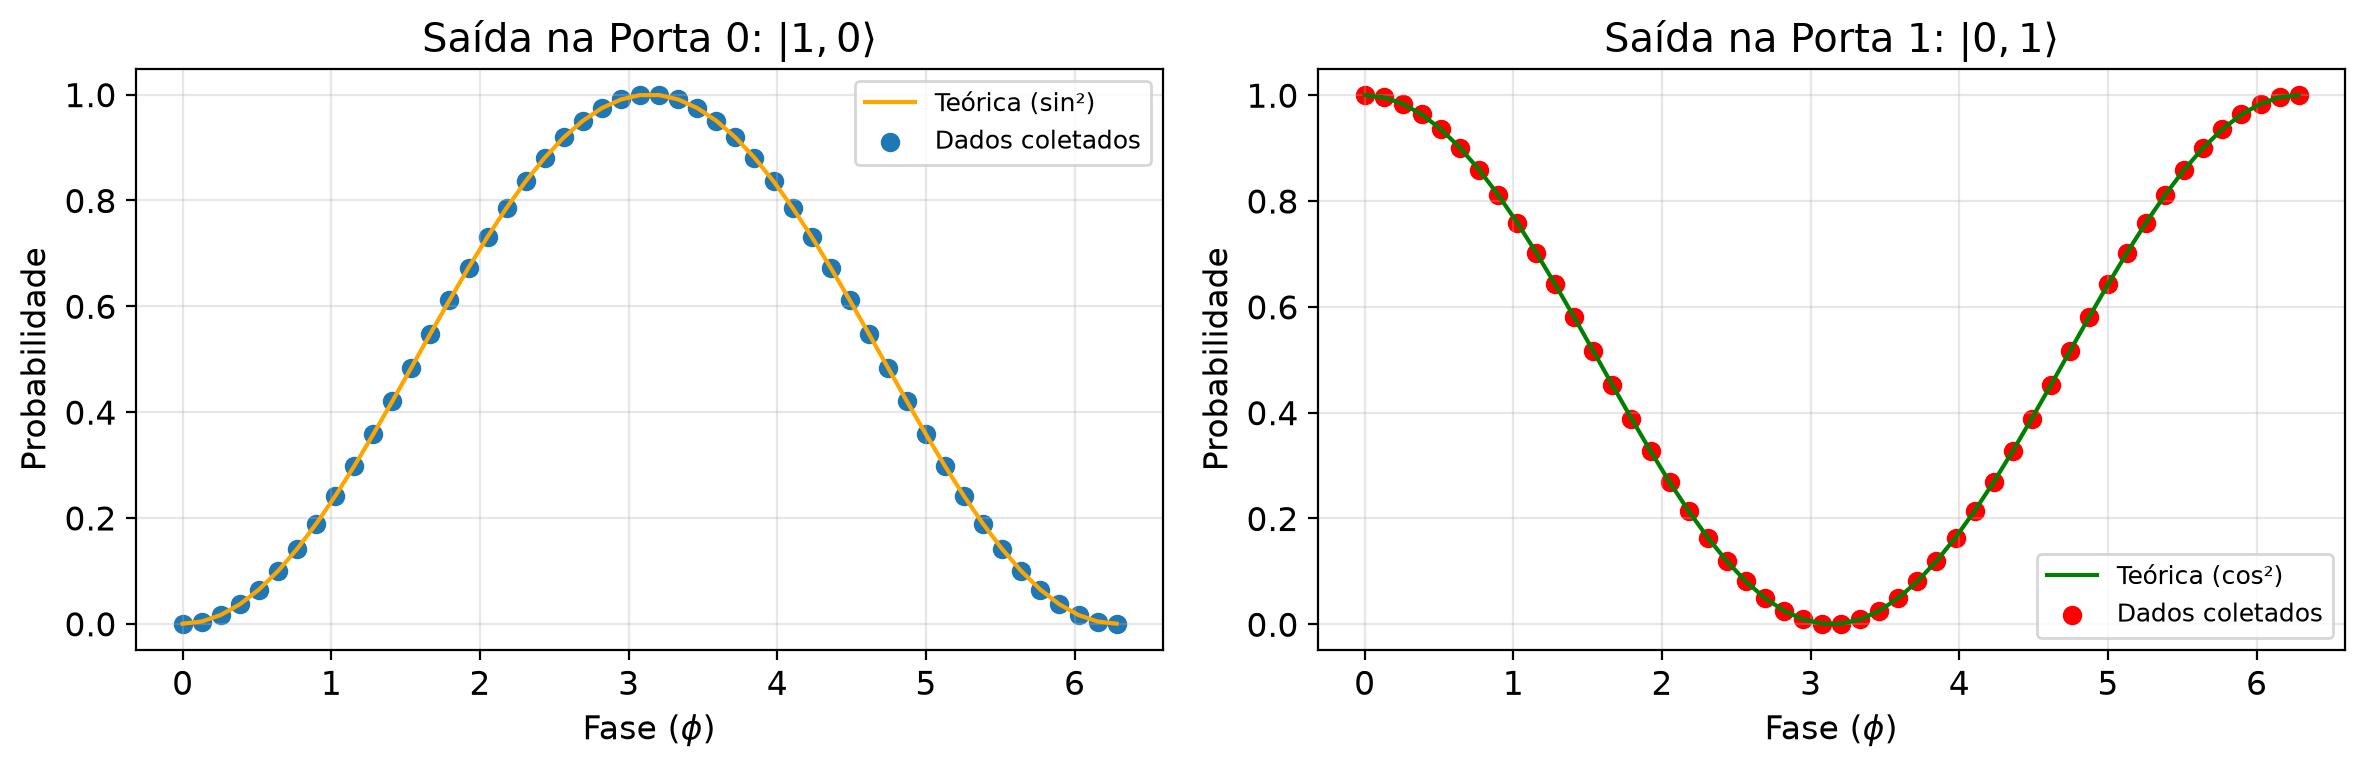

In [12]:
phis = np.linspace(0., 2*np.pi, 50)
probs = []
probs_up = []

state = pcvl.BasicState([1,0])
state1  = pcvl.BasicState('|1,0>')
ress = []

for phi in phis:
    proc = pcvl.Processor("SLOS", michelson(phi))
    proc.with_input(state)
    proc.min_detected_photons_filter(1) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()["results"]
    ress.append(res)
    
    
    probs.append(res.get(state, 0.0)) # resultados para o estado do fóton embaixo
    probs_up.append(res.get(pcvl.BasicState([0,1]), 0.0))    # resultados para o estado do fóton em cima

circuit = michelson(np.pi)
# 2 modos, 1 BS



teor_10 = [np.sin(phi/2)**2 for phi in phis]
teor_01 = [np.cos(phi/2)**2 for phi in phis]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Gráfico 1: Porta 0 (Probabilidade do estado |1,0>) ---
ax1.plot(phis, teor_10, label='Teórica (sin²)', c='orange')
ax1.scatter(phis, probs, label='Dados coletados')
ax1.set_xlabel('Fase ($\phi$)')
ax1.set_ylabel('Probabilidade')
ax1.set_title('Saída na Porta 0: $|1,0\\rangle$')
ax1.legend(loc="upper right", fontsize=9)

# --- Gráfico 2: Porta 1 (Probabilidade do estado |0,1>) ---
ax2.plot(phis, teor_01, label='Teórica (cos²)', c='green')
ax2.scatter(phis, probs_up, label='Dados coletados', c='red')
ax2.set_xlabel('Fase ($\phi$)')
ax2.set_ylabel('Probabilidade')
ax2.set_title('Saída na Porta 1: $|0,1\\rangle$')
ax2.legend(loc="lower right", fontsize=9)

# Ajusta o espaçamento para não sobrepor os textos
plt.tight_layout()
plt.show()

Sabemos que para um divisor de feixes temos que:

$$
\sqrt{R} = \sin \frac\theta 2 \\
\sqrt{T} = \cos \frac\theta 2
$$

Sendo $\theta$ o ângulo, em que posicionamos o divisor referente ao feixe. Note que para nós a transmitância vai representar a passagem de um fóton de um modo ao outro, já a reflectância vai mantê-lo no mesmo modo. Ou seja, se maximixo a transmitância $\theta = np.pi$ e incializo meu sistema em $|1,0\rangle$ minha medição nos dará $|0,1\rangle$. Já, se fizermos o contrário, $\theta = 2\pi$, veremos o estado $|1,0\rangle$ ao final (foi refletido, logo permanece no mesmo estado).




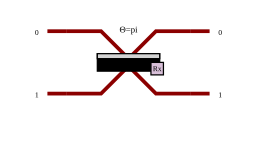

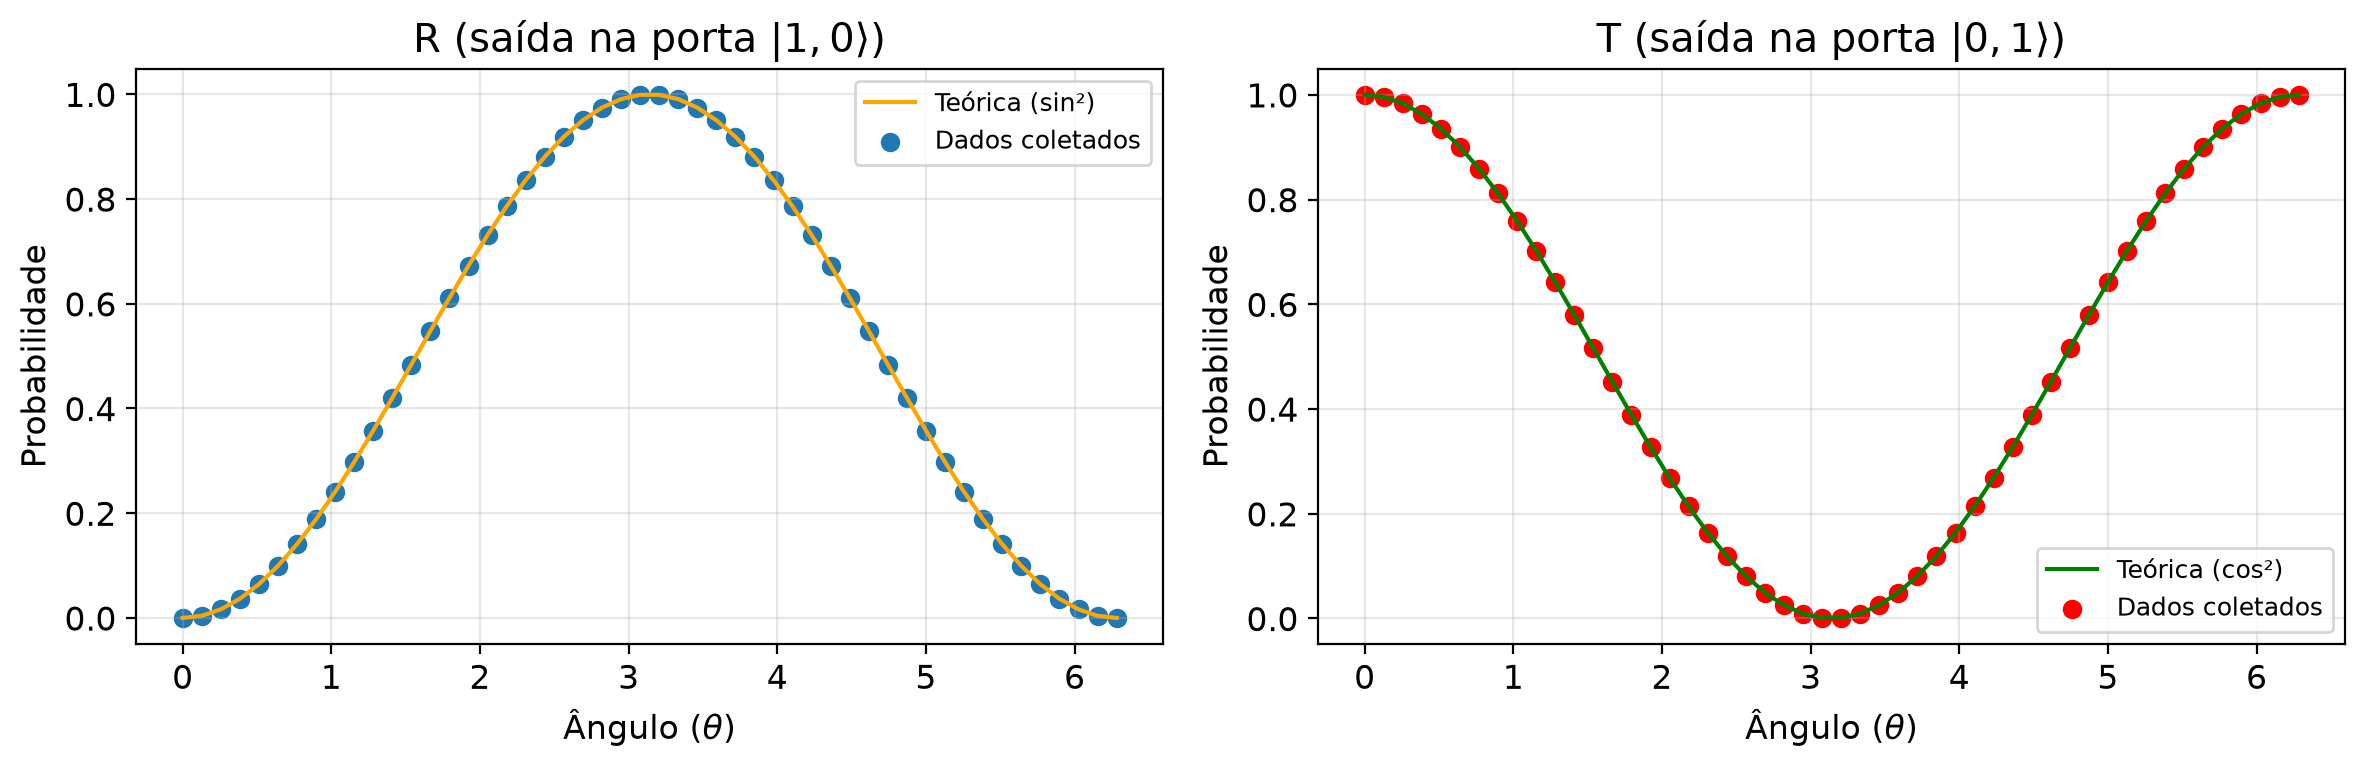

In [29]:
# One photon, one 50:50 beamsplitter.
def beamsplitter(phi):
    return pcvl.Circuit(2)  // pcvl.BS(theta = phi)

phis = np.linspace(0., 2*np.pi, 50)
prob_R = []
prob_T = []

state10 = pcvl.BasicState('|1,0>') # estado inicial = estado final (reflexao)
state01 = pcvl.BasicState('|0,1>') # estado inicial != estado final (transmissao)
ress = []


for phi in phis:
    proc = pcvl.Processor("SLOS", michelson(phi))
    proc.with_input(state)
    proc.min_detected_photons_filter(1) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()["results"]
    ress.append(res)    
    prob_R.append(res.get(state10, 0.0)) # resultados para o estado do fóton embaixo
    prob_T.append(res.get(state01, 0.0))    # resultados para o estado do fóton em cima

circuit = michelson(np.pi)
display(pcvl.pdisplay(circuit))

#---

trans = [np.cos(phi/2)**2 for phi in phis]


reflete = [np.sin(phi/2)**2 for phi in phis]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Gráfico 1: Porta 0 (Probabilidade do estado |1,0>) ---
ax1.plot(phis, reflete, label='Teórica (sin²)', c='orange')
ax1.scatter(phis, prob_R, label='Dados coletados')
ax1.set_xlabel(r'Ângulo ($\theta$)')
ax1.set_ylabel('Probabilidade')
ax1.set_title('R (saída na porta $|1,0\\rangle$)')
ax1.legend(loc="upper right", fontsize=9)

# --- Gráfico 2: Porta 1 (Probabilidade do estado |0,1>) ---
ax2.plot(phis, trans, label='Teórica (cos²)', c='green')
ax2.scatter(phis, prob_T, label='Dados coletados', c='red')
ax2.set_xlabel(r'Ângulo ($\theta$)')
ax2.set_ylabel('Probabilidade')
ax2.set_title('T (saída na porta $|0,1\\rangle$)')
ax2.legend(loc="lower right", fontsize=9)

# Ajusta o espaçamento para não sobrepor os textos
plt.tight_layout()
plt.show()

Esse breve exercício foi apenas para reforçar a ideia de que o funcionamento do computador está intimamente relacionado com a implementação de I.M.Z

### Hong-Ouh Mandel (HOM) Interferometer

O experimento HOM explora uma ideia simples a respeito da existência de fótons únicos simplismente com um divisor de feixes. O experimento original é um pouco mais complicado do que isso, mas vamos estudar os resultados.


Probabilidades exatas:
  |0,2>: 0.500
  |2,0>: 0.500

1000 contagens (clicks!):
  |2,0>: 501
  |0,2>: 499

Probabilidades obtidas:
  |2,0>: 0.501
  |0,2>: 0.499


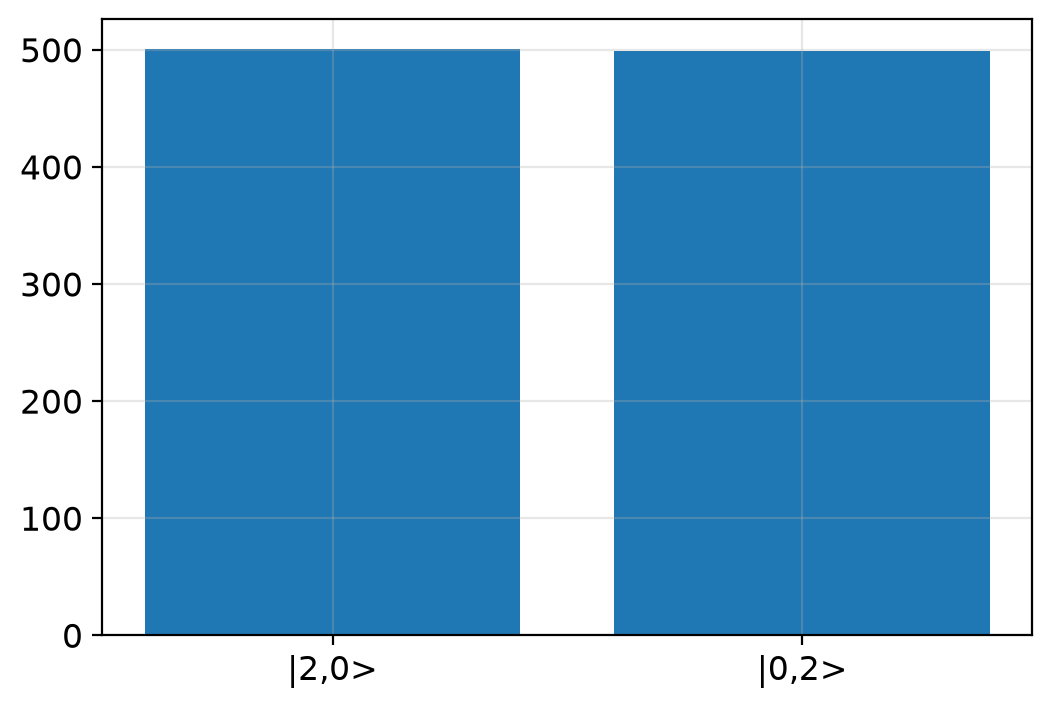

In [68]:
def simple_HOM(theta):
    return pcvl.Circuit(2) // pcvl.BS(theta = theta)
    
ket0 = pcvl.BasicState('|1,1>')
proc = pcvl.Processor('SLOS', simple_HOM(np.pi/2))
proc.with_input(ket0)
proc.min_detected_photons_filter(0) ### detecta com no minimo 1 fóton


sampler =  pcvl.algorithm.Sampler(proc)
result = sampler.probs()
probs = result["results"] # define as probabilidades exatas (analíticas)
print("Probabilidades exatas:")
for state, p in probs.items():
    print(f"  {state}: {p:.3f}")

# Permite simular resultados "reais":
n_sample = 1000
counts = sampler.sample_count(n_sample)["results"]
print("\n1000 contagens (clicks!):")
for state, c in counts.items():
    print(f"  {state}: {c}")
    
print('\nProbabilidades obtidas:')
for state,c in counts.items():
    print(f"  {state}: {c/n_sample}")
    
# podemos visualizar como um histograma:
plt.bar([str(state) for state in counts.keys()], counts.values())
plt.show()

Com nosso divisor de feixe 50:50 vimos que não é possível medir coincidências. Porém, isso não é verdade para todo $T$ (transmitância) e $R$ (refletância), é possível fazer contas similares as feitas anteriormente só que com $T$ e $R$ arbitrários para mostrar que:
$$
P(|11\rangle) = P_{coinc} = (T - R)^2 = (2T - 1)^2 = (1 - 2R)^2
$$
Podemos checar isso variando a refletância do nosso BS.


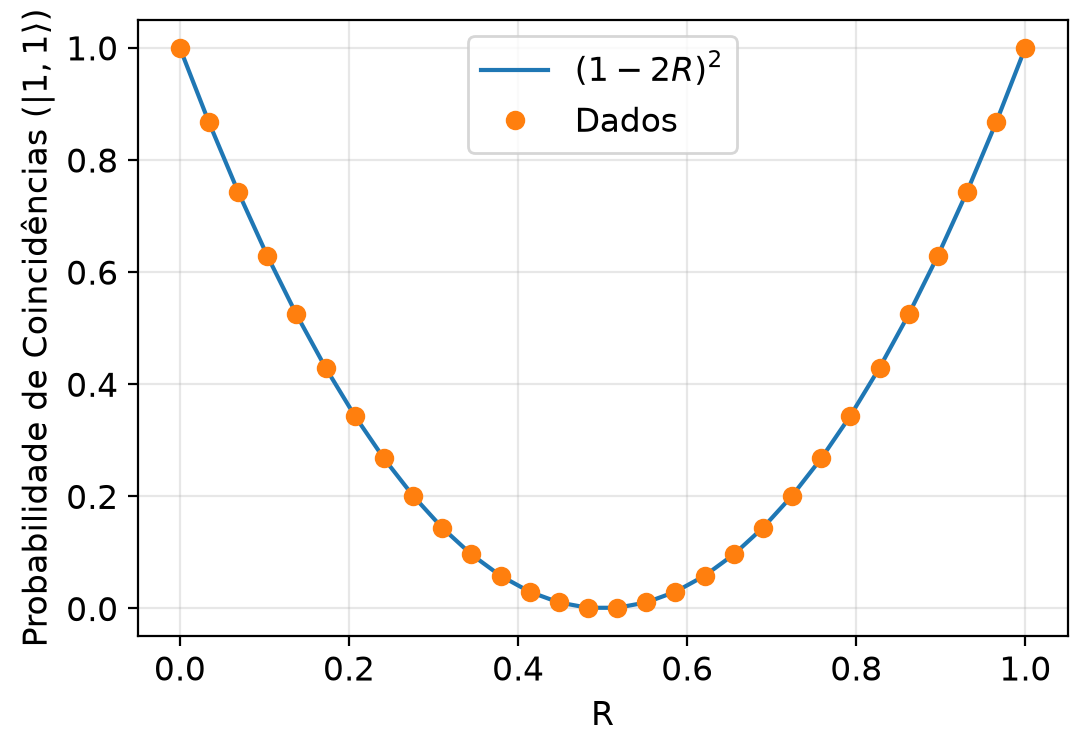

In [65]:
rs = np.linspace(0,1,30)

prob11 = []

for r in rs:
    proc = pcvl.Processor("SLOS", simple_HOM(pcvl.BS.r_to_theta(r)))
    proc.with_input(ket0)
    proc.min_detected_photons_filter(1) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()["results"]   
    prob11.append(res.get(ket0, 0.))
    
plt.plot(rs, (1-2*rs)**2, label = r'$(1-2R)^2$')
plt.plot(rs,prob11, 'o',label = 'Dados')



plt.xlabel('R')
plt.ylabel(r'Probabilidade de Coincidências ($|1,1\rangle$)')
plt.legend()
plt.show()

O experimento clássico de HOM está esquematizado abaixo (ilustração retirada das palestras do Tim):

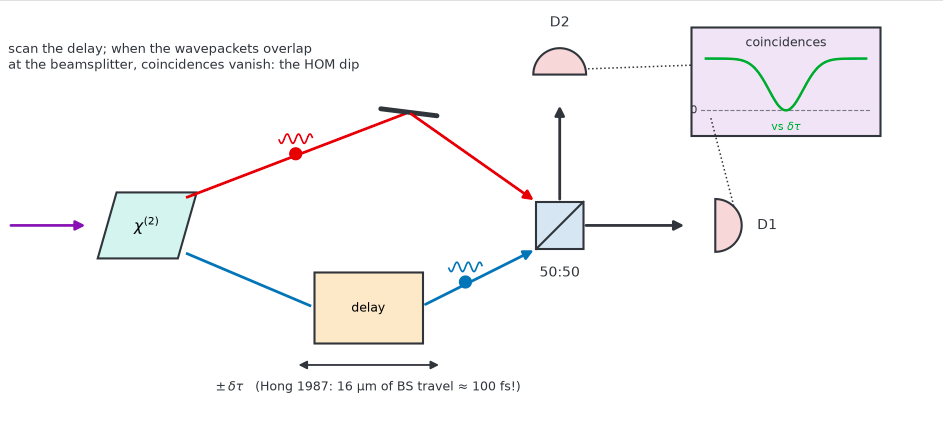


O processo consiste em utilizar uma fonte SPDC tipo 1, que produz fótons correlacionados espacilamente e temporalmente. Se permitirmos que esses fótons cheguem no beam splitter no exato mesmo tempo veremos que a probabilidade de coincidência é nula, porém a medida que aumentamos o atraso de um dos fótons (ou seja, diminuimos a indistinguibilidade) aumentamos a contagem de coincidências. 

No nosso caso, apesar de existir uma função de delay, podemos configurar a indistinguibilidade dos fótons já na fonte. Como já foi visto anteriormente um dos modelos de ruído possíveis é a configuração de indistinguibilidade, sendo assim, vamos simular esse mesmo experimento variando quão distinguíveis esses fótons são. 

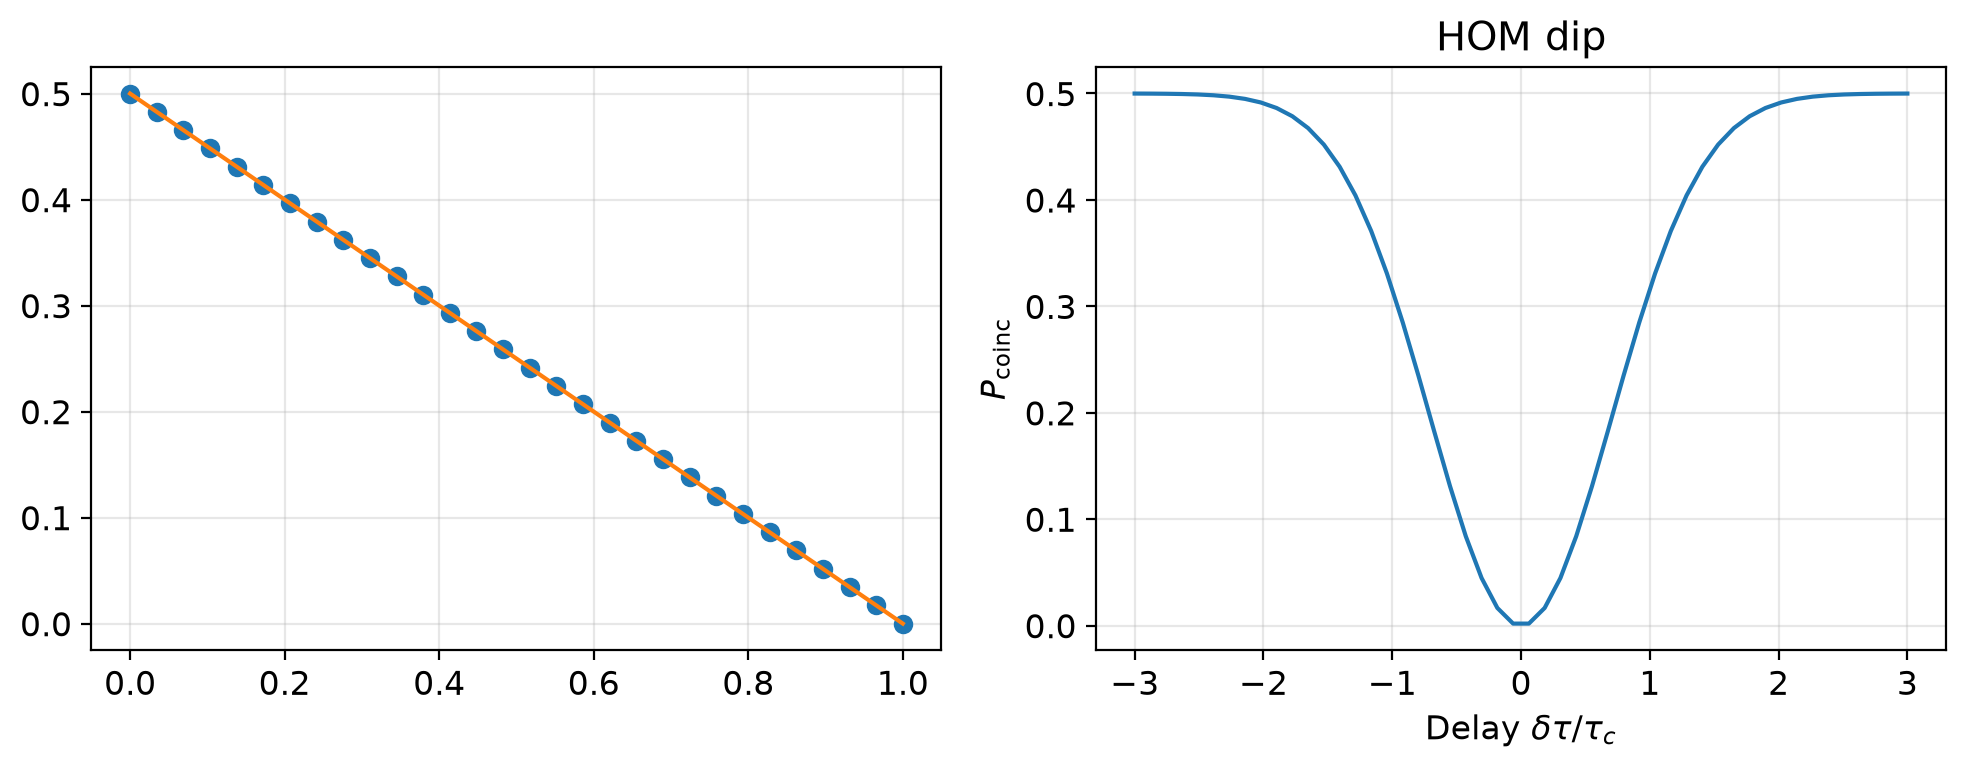

In [86]:
indist = np.linspace(0,1,30)

prob11 = []

for i in indist:
    proc = pcvl.Processor("SLOS", simple_HOM(pcvl.BS.r_to_theta(0.5)),noise= pcvl.NoiseModel(indistinguishability = i) )
    proc.with_input(ket0)
    proc.min_detected_photons_filter(1) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()["results"]   
    prob11.append(res.get(ket0, 0.))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(indist,prob11, 'o',label = 'Dados')
ax1.plot(indist, (1/2)*(1 - indist), label = r'$\frac{1}{2}(1 - I)$')

delay = np.linspace(-3,3,50)
I_delay = np.exp(-delay**2)

### Para pegarmos a P_coincidencia para os valores definidos de indistinguibilidade vamos interpolar 
### os dados com os valores já obtidos

p_dip = np.interp(I_delay, indist, prob11)

# y que desejamos = np.interp(x que queremos testar, x que já testamos, y que obtivemos a partir do x testado)
ax2.plot(delay, p_dip, "-")
ax2.set_xlabel(r"Delay $\delta\tau / \tau_c$")
ax2.set_ylabel(r"$P_{\rm coinc}$")
ax2.set_title("HOM dip")
plt.tight_layout(); plt.show()



ax1.set_xlabel('Indistinguibilidade')
ax1.set_ylabel(r'Probabilidade de Coincidências ($|1,1\rangle$)')
ax1.legend()
plt.show()